In [1]:
from pathlib import Path
import sys

import numpy as np

ROOT = Path.cwd()
if ROOT.name == "demo":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from numcompute.io import iter_csv_chunks
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.tree import DecisionTreeClassifier

CSV_PATH = ROOT / "demo" / "stream_data.csv"
chunk_sizes = [
    len(chunk)
    for chunk in iter_csv_chunks(CSV_PATH, chunk_size=20, skip_header=1)
]
print("Chunks:", len(chunk_sizes))
print("Sizes:", chunk_sizes)

Chunks: 12
Sizes: [20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20, 20]


**Incremental training**
The first two chunks fill the 40-sample buffer. Later chunks are scored before the model is updated.

In [5]:
pipe = Pipeline([
    ("model", DecisionTreeClassifier(max_depth=5, buffer_size=40)),
])
trainer = StreamTrainer(pipe)

for chunk_number, chunk in enumerate(
    iter_csv_chunks(CSV_PATH, chunk_size=20, skip_header=1),
    start=1,
):
    X_chunk = chunk[:, :2]
    y_chunk = chunk[:, 2].astype(int)

    if chunk_number <= 2:
        trainer.fit_chunk(X_chunk, y_chunk)
        print("Chunk", chunk_number, ": filling the first buffer")
    else:
        score = trainer.score_chunk(X_chunk, y_chunk)
        trainer.fit_chunk(X_chunk, y_chunk)
        print(
            "Chunk", chunk_number,
            "accuracy:", round(score, 3),
            "cumulative:", round(trainer.logs[-1]["cumulative_accuracy"], 3),
        )

print("Scored chunks:", len(trainer.logs))

Chunk 1 : filling the first buffer
Chunk 2 : filling the first buffer
Chunk 3 accuracy: 0.85 cumulative: 0.85
Chunk 4 accuracy: 0.95 cumulative: 0.9
Chunk 5 accuracy: 0.8 cumulative: 0.867
Chunk 6 accuracy: 0.8 cumulative: 0.85
Chunk 7 accuracy: 0.7 cumulative: 0.82
Chunk 8 accuracy: 0.9 cumulative: 0.833
Chunk 9 accuracy: 1.0 cumulative: 0.857
Chunk 10 accuracy: 0.9 cumulative: 0.863
Chunk 11 accuracy: 0.7 cumulative: 0.844
Chunk 12 accuracy: 0.9 cumulative: 0.85
Scored chunks: 10


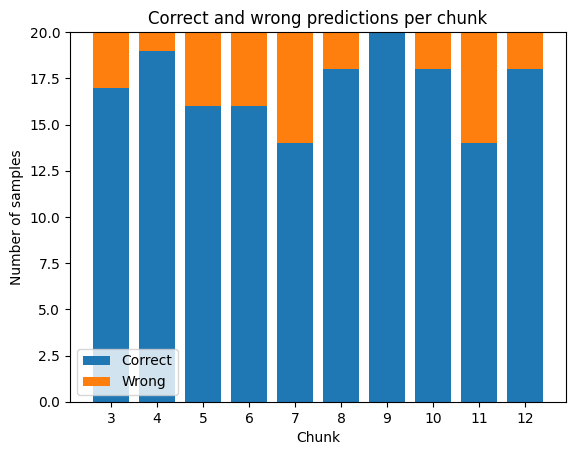

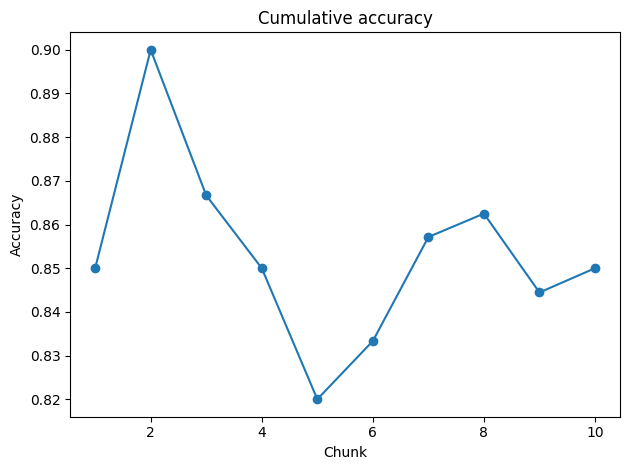

Latest approximate model memory: 1.16 KiB


In [6]:
import matplotlib.pyplot as plt

from numcompute_stream.visualise import plot_metric_over_time

chunk_numbers = list(range(3, 3 + len(trainer.logs)))
correct_counts = [
    round(log["accuracy"] * log["n_samples"]) for log in trainer.logs
]
wrong_counts = [
    log["n_samples"] - correct
    for log, correct in zip(trainer.logs, correct_counts)
]

fig, ax = plt.subplots()
ax.bar(chunk_numbers, correct_counts, label="Correct")
ax.bar(chunk_numbers, wrong_counts, bottom=correct_counts, label="Wrong")
ax.set_xlabel("Chunk")
ax.set_ylabel("Number of samples")
ax.set_title("Correct and wrong predictions per chunk")
ax.set_xticks(chunk_numbers)
ax.legend()
plt.show()

cumulative_accuracy = [
    log["cumulative_accuracy"] for log in trainer.logs
]
trend_fig = plot_metric_over_time(
    cumulative_accuracy, "Cumulative accuracy", "Accuracy"
)

print(
    "Latest approximate model memory:",
    round(trainer.logs[-1]["model_memory_bytes"] / 1024, 2),
    "KiB",
)